# 02 · Análisis predictivo de deserción

## Introducción
La variable objetivo `desertor` indica si el paciente abandonó el itinerario
terapéutico. En fisura labiopalatina la deserción suele concentrarse cuando
aumentan las **citas perdidas (no-show)**, la **distancia al centro** y la
**vulnerabilidad socioeconómica**, y cuando falta apoyo psicológico.

Este notebook trabaja exclusivamente con `dataset_final_limpio.csv`
(unión real de las 6 fuentes de `data/raw/`).

## Hipótesis
- H1: los desertores acumulan más `citas_perdidas_noshow`.
- H2: la tasa de deserción decrece al subir `nivel_socioeconomico_ord`.
- H3: mayor `distancia_hospital_km` se asocia a más deserción, sobre todo sin apoyo psicológico.


In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 110,
})

CANDIDATES = [Path.cwd(), Path.cwd().parent]
ROOT = next(
    path for path in CANDIDATES
    if (path / "data" / "processed" / "dataset_final_limpio.csv").exists()
    or (path / "data" / "raw" / "dataset_desercion_fisura_bilabial.csv").exists()
)
PROCESSED = ROOT / "data" / "processed" / "dataset_final_limpio.csv"
RAW = ROOT / "data" / "raw"
print(f"Raíz del proyecto: {ROOT}")


Raíz del proyecto: C:\Users\richa\Downloads\Proyecto-predicci-n-de-desertamiento-del-tratamiento-de-fisura-bilabial


In [2]:
df = pd.read_csv(PROCESSED)
print(df.shape)
print(df["desertor"].value_counts().rename({0: "continúa", 1: "deserta"}))
print("Tasa global:", round(float(df["desertor"].mean()), 4))
print(df.groupby("cohorte")["desertor"].agg(["count", "mean"]))
df.head()


(3500, 31)
desertor
deserta     2612
continúa     888
Name: count, dtype: int64
Tasa global: 0.7463
         count   mean
cohorte              
v1         500  0.940
v2        3000  0.714


,id_paciente,cohorte,tipo_fisura,fisura_Completa,fisura_Asimetrica,fisura_Incompleta,edad_inicio_meses,distancia_hospital_km,nivel_socioeconomico,nivel_socioeconomico_ord,...,fistula_palatina_residual,complicaciones_quirurgicas,peso_z_score_2anos,citas_terapia_programadas,citas_terapia_asistidas,ratio_asistencia_terapia,hipoacusia_conductiva,grado_hipernasalidad,insuficiencia_velofaringea_ivf,desertor
0,PAC-1000,v1,Completa,1,0,0,6,46.9,Alto,4,...,1,1,0.16,20,15,0.750000,0,2,1,1
1,PAC-1001,v1,Asimetrica,0,1,0,1,59.3,Bajo,0,...,0,0,-0.37,47,46,0.978723,0,3,1,1
2,PAC-1002,v1,Incompleta,0,0,1,9,9.2,Medio,2,...,0,0,-0.25,43,31,0.720930,1,0,0,1
3,PAC-1003,v1,Incompleta,0,0,1,1,88.2,Medio,2,...,0,0,-1.07,22,14,0.636364,0,2,1,1
4,PAC-1004,v1,Completa,1,0,0,5,19.1,Bajo,0,...,0,0,-2.21,35,33,0.942857,1,3,1,1


## Variables del modelo conceptual
| Bloque | Variables |
|---|---|
| Objetivo | `desertor` |
| Adherencia | `citas_perdidas_noshow`, `citas_asistidas`, `ratio_asistencia_terapia` |
| Acceso | `distancia_hospital_km`, `nivel_socioeconomico`, `ingresos_mensuales_usd`, `apoyo_psicologico` |
| Clínica | `cirugias_programadas`, `complicaciones_quirurgicas`, `tipo_fisura` |


## Desbalance de la etiqueta
v1 está fuertemente sesgada hacia deserción; v2 es más heterogénea.
Eso obliga a `scale_pos_weight` en XGBoost; no se submuestrea el CSV analítico.


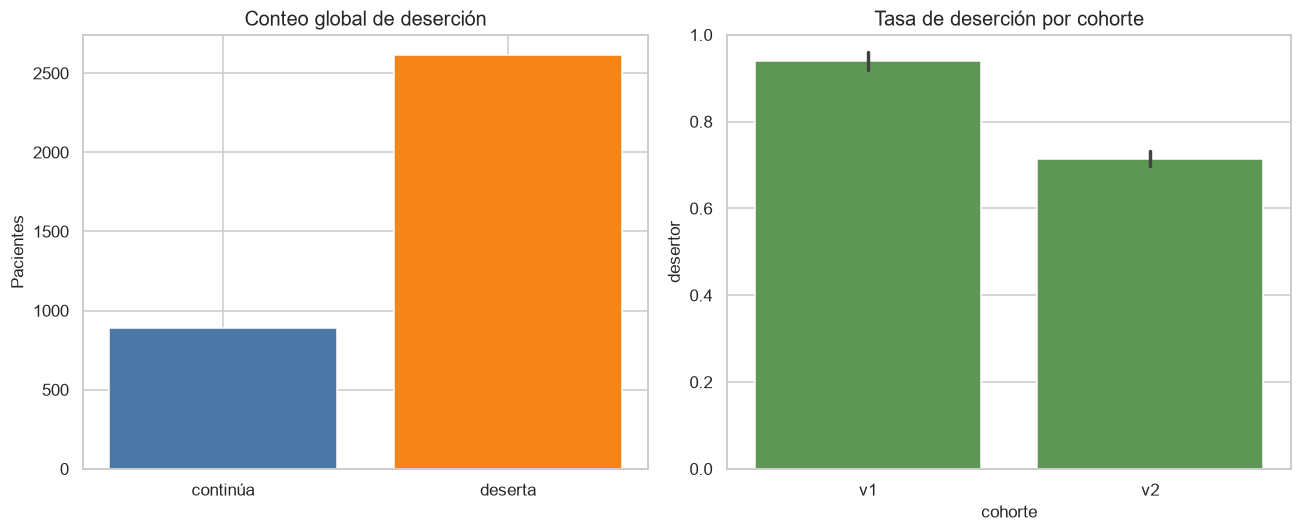

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
order = ["continúa", "deserta"]
counts = df["desertor"].map({0: "continúa", 1: "deserta"}).value_counts().reindex(order)
axes[0].bar(counts.index, counts.values, color=["#4c78a8", "#f58518"])
axes[0].set_title("Conteo global de deserción")
axes[0].set_ylabel("Pacientes")
sns.barplot(
    data=df, x="cohorte", y="desertor", errorbar=("ci", 95), ax=axes[1], color="#54a24b",
)
axes[1].set_ylim(0, 1)
axes[1].set_title("Tasa de deserción por cohorte")
fig.tight_layout()
plt.show()


## Boxplot detallado: citas perdidas (no-show) según deserción

Gráfico solicitado de forma explícita: distribución de inasistencias condicionada a `desertor`,
con cuartiles, atípicos y media muestral.


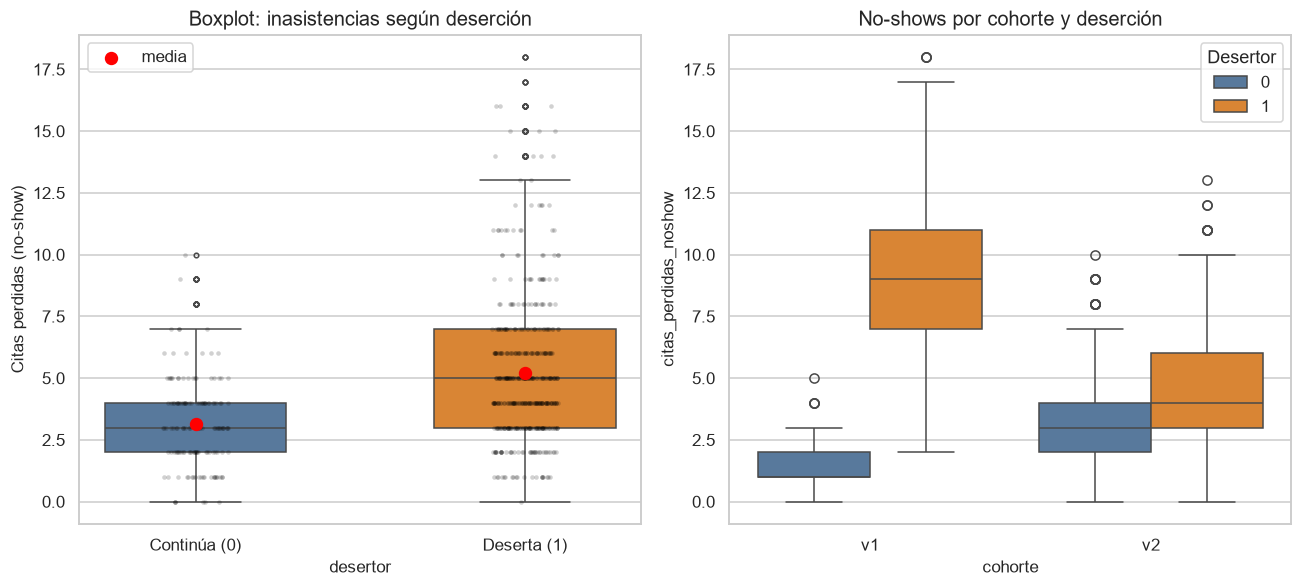

,count,mean,median,std,min,max
desertor,,,,,,
continúa,888,3.127,3.0,1.845,0,10
deserta,2612,5.227,5.0,2.907,0,18


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
palette = {0: "#4c78a8", 1: "#f58518"}
sns.boxplot(
    data=df,
    x="desertor",
    y="citas_perdidas_noshow",
    hue="desertor",
    palette=palette,
    width=0.55,
    fliersize=3,
    legend=False,
    ax=axes[0],
)
sns.stripplot(
    data=df.sample(min(len(df), 600), random_state=7),
    x="desertor",
    y="citas_perdidas_noshow",
    color="black",
    alpha=0.18,
    size=3,
    ax=axes[0],
)
means = df.groupby("desertor")["citas_perdidas_noshow"].mean()
axes[0].scatter([0, 1], means.reindex([0, 1]), color="red", s=60, zorder=5, label="media")
axes[0].set_xticks([0, 1], ["Continúa (0)", "Deserta (1)"])
axes[0].set_ylabel("Citas perdidas (no-show)")
axes[0].set_title("Boxplot: inasistencias según deserción")
axes[0].legend(loc="upper left")

sns.boxplot(
    data=df,
    x="cohorte",
    y="citas_perdidas_noshow",
    hue="desertor",
    palette=palette,
    ax=axes[1],
)
axes[1].set_title("No-shows por cohorte y deserción")
axes[1].legend(title="Desertor")
fig.tight_layout()
plt.show()

stats_noshow = (
    df.groupby("desertor")["citas_perdidas_noshow"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)
stats_noshow.index = stats_noshow.index.map({0: "continúa", 1: "deserta"})
stats_noshow


## Factor socioeconómico y distancia al centro


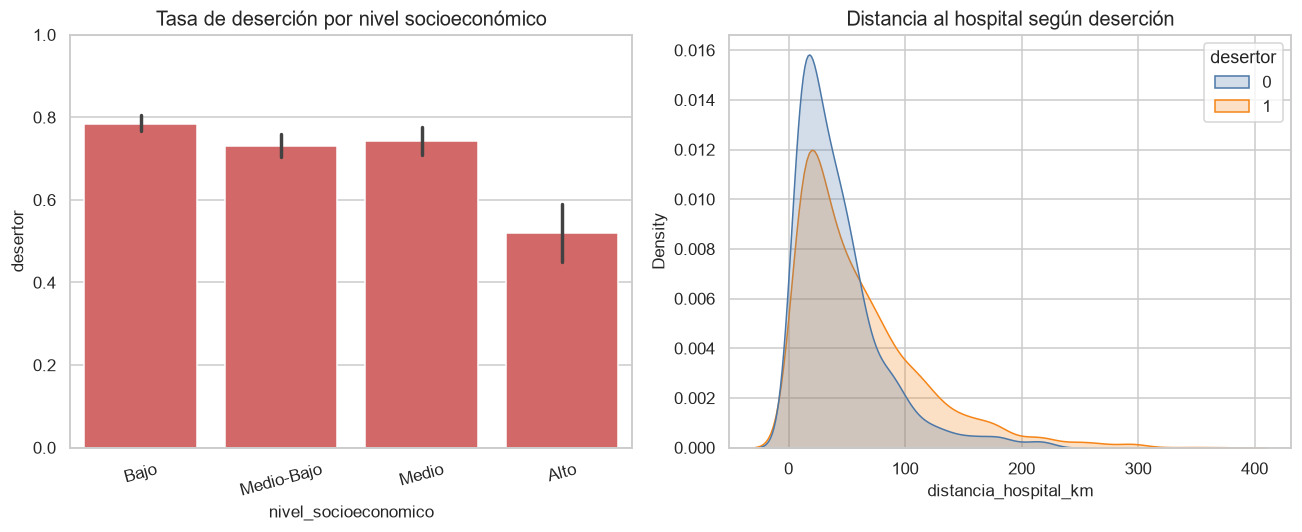

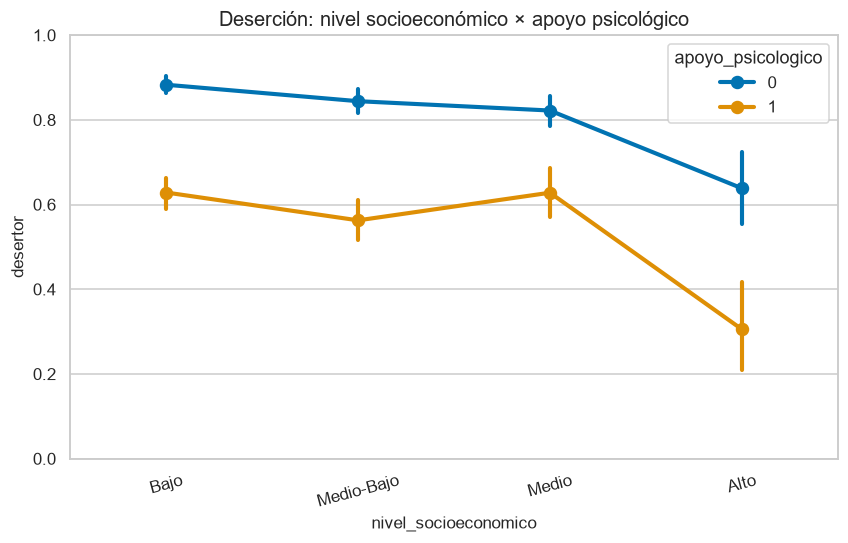

,n,tasa,noshow
nivel_socioeconomico,,,
Bajo,1642,0.784,0.784
Medio-Bajo,1016,0.731,0.731
Medio,640,0.744,0.744
Alto,202,0.520,0.520


In [5]:
ses_order = ["Bajo", "Medio-Bajo", "Medio", "Alto"]
present = [nivel for nivel in ses_order if nivel in set(df["nivel_socioeconomico"])]
tasas = (
    df.groupby("nivel_socioeconomico")["desertor"]
    .agg(n="count", tasa="mean", noshow="mean")
    .reindex(present)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(
    data=df, x="nivel_socioeconomico", y="desertor",
    order=present, errorbar=("ci", 95), ax=axes[0], color="#e45756",
)
axes[0].set_ylim(0, 1)
axes[0].set_title("Tasa de deserción por nivel socioeconómico")
axes[0].tick_params(axis="x", rotation=15)

sns.kdeplot(
    data=df, x="distancia_hospital_km", hue="desertor",
    fill=True, common_norm=False, ax=axes[1], palette=palette,
)
axes[1].set_title("Distancia al hospital según deserción")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
sns.pointplot(
    data=df,
    x="nivel_socioeconomico",
    y="desertor",
    hue="apoyo_psicologico",
    order=present,
    errorbar=("ci", 95),
    ax=ax,
)
ax.set_ylim(0, 1)
ax.set_title("Deserción: nivel socioeconómico × apoyo psicológico")
ax.tick_params(axis="x", rotation=15)
plt.show()
tasas.round(3)


## Correlación con la etiqueta y entre predictores
Se usan solo numéricas del modelo conceptual. Una correlación alta entre no-show y
`desertor` no implica causalidad, pero sí prioridad clínica de seguimiento de inasistencias.


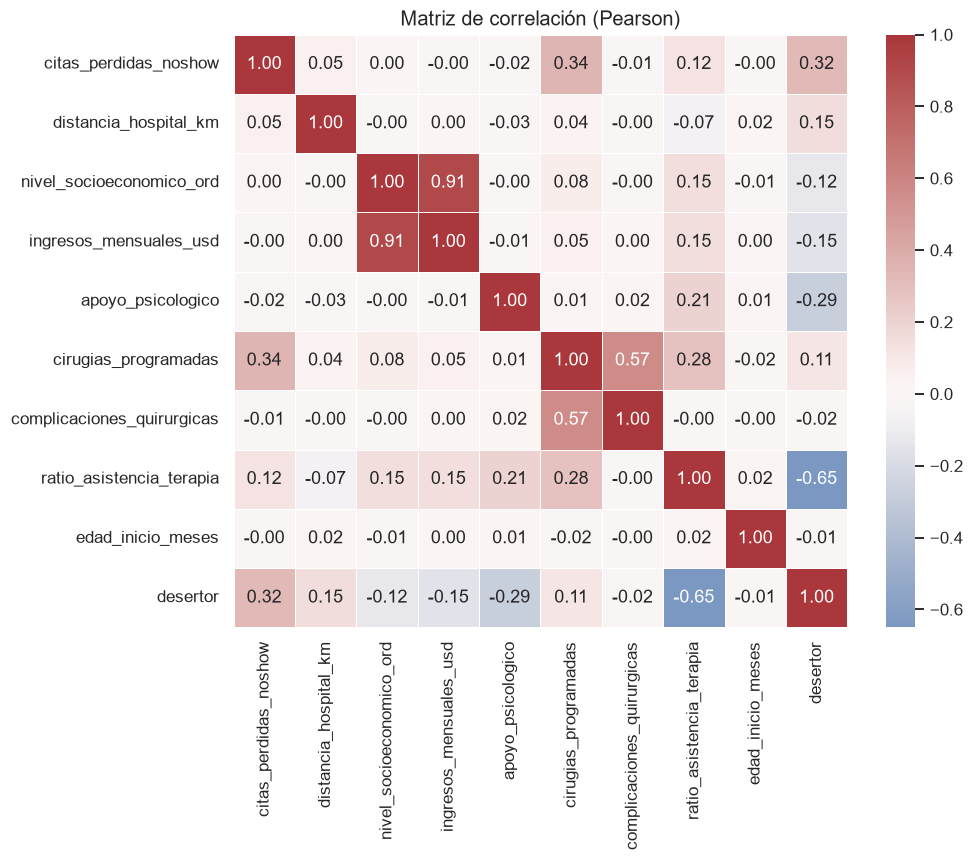

,corr_desertor
ratio_asistencia_terapia,-0.650368
citas_perdidas_noshow,0.322914
apoyo_psicologico,-0.285004
distancia_hospital_km,0.152356
ingresos_mensuales_usd,-0.148086
nivel_socioeconomico_ord,-0.122899
cirugias_programadas,0.111170
complicaciones_quirurgicas,-0.016928
edad_inicio_meses,-0.012574


In [6]:
features = [
    "citas_perdidas_noshow",
    "distancia_hospital_km",
    "nivel_socioeconomico_ord",
    "ingresos_mensuales_usd",
    "apoyo_psicologico",
    "cirugias_programadas",
    "complicaciones_quirurgicas",
    "ratio_asistencia_terapia",
    "edad_inicio_meses",
    "desertor",
]
corr = df[features].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="vlag", center=0,
    linewidths=0.4, ax=ax,
)
ax.set_title("Matriz de correlación (Pearson)")
plt.show()

asoc = (
    corr["desertor"]
    .drop(labels=["desertor"])
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .to_frame("corr_desertor")
)
asoc


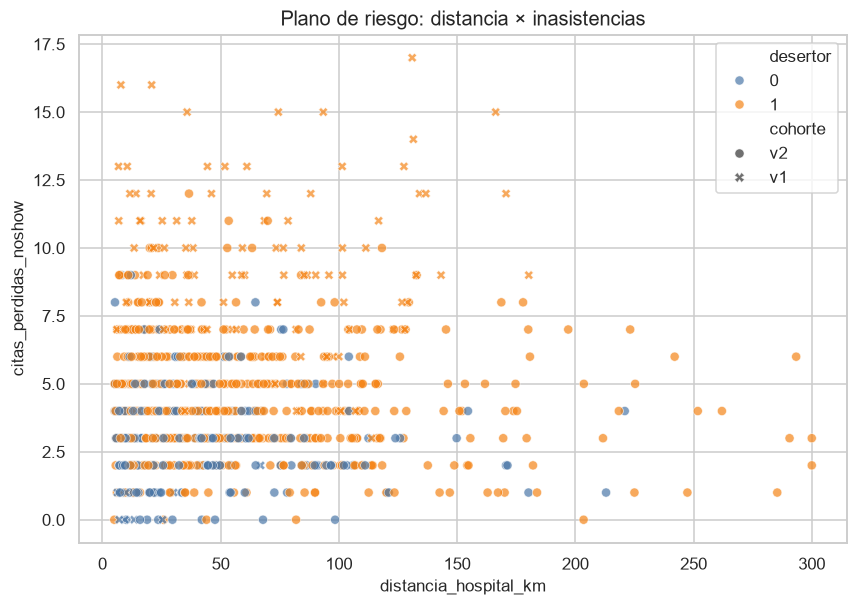

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
muestra = df.sample(min(len(df), 900), random_state=21)
sns.scatterplot(
    data=muestra,
    x="distancia_hospital_km",
    y="citas_perdidas_noshow",
    hue="desertor",
    style="cohorte",
    alpha=0.7,
    ax=ax,
    palette=palette,
)
ax.set_title("Plano de riesgo: distancia × inasistencias")
plt.show()


## Conclusiones predictivas
1. El **boxplot de no-shows** es la señal más accionable: los desertores concentran
   más citas perdidas, con cola larga de inasistencias reiteradas.
2. El **gradiente socioeconómico** y los **ingresos** se alinean con la deserción;
   el apoyo psicológico atenúa la tasa en varios estratos.
3. La **distancia al hospital** desplaza la masa de desertores hacia trayectos más largos;
   combinada con no-shows define un plano de riesgo de seguimiento.
4. El desbalance de clases (sobre todo v1) impide usar accuracy como métrica única.
   El backend debe entrenar XGBoost con `scale_pos_weight` sobre este CSV limpio.
